# Multiple Linear Regression: Predicting Filter Loading

Target: **Filter loading (ml/(cm^2*s))**. Predictors: numeric process/membrane variables plus `Solution (cleaned)` and `Filter material (cleaned)` as categorical features.


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [2]:
df = pd.read_csv("database.csv")
df.shape


(300, 19)

## Drop columns

Per request, drop `Solution (breif description)`, `Filter material` (the raw/uncleaned duplicate of `Filter material (cleaned)`), and `Permiability (L/m^2 hr bar)`. Also drop `Source (DOI)` (a citation, not a feature) and the stray flux-converter note column that ended up as a column header.


In [3]:
drop_cols = [
    "Solution (breif description)",
    "Filter material",
    "Permiability (L/m^2 hr bar)",
    "Source (DOI)",
    "Flux to flow rate converter: https://www.cytivalifesciences.com/en/us/support/online-tools/crossflow-and-normal-flow-filtration/flux-converter ",
]
df = df.drop(columns=drop_cols)
df.columns = df.columns.str.strip()
df.head()


,Solution (cleaned),Filter material (cleaned),Filter loading (ml/(cm^2*s)),Pore size (µm),Effective Area (cm^2),Duration (min),Volume (ml),Pressure drop (bar),Max Flux (L/m^2-hr),Volumetric Flux (L/m^2 hr),Starting Flux (L/m^2 h),Flow Rate (ml/min),Mean flow resistance (m/kg),Concentration (g/L)
0,Wort,polytetrafluoroethylene (PTFE),NaN,0.1,NaN,30,NaN,3.0,NaN,NaN,NaN,0.1666666667,NaN,0.081
1,Wort,polytetrafluoroethylene (PTFE),NaN,0.2,NaN,30,NaN,3.0,NaN,NaN,NaN,0.1666666667,NaN,0.081
2,Wort,polyamide(PA),NaN,0.04,NaN,30,NaN,3.0,NaN,NaN,NaN,0.1666666667,NaN,0.081
3,Wort,polyamide(PA),NaN,0.1,NaN,30,NaN,3.0,NaN,NaN,NaN,0.1666666667,NaN,0.081
4,Wort,polyamide(PA),NaN,0.2,NaN,30,NaN,3.0,NaN,NaN,NaN,0.1666666667,NaN,0.081


## Clean messy numeric-as-text columns

Several numeric columns were scraped as text: thousands separators ("5,980"), a literal range ("0.05 x 0.125"), or units duplicated with the value. `parse_numeric` strips commas, pulls out every number in the cell, and averages them (so a range collapses to its midpoint).

`Mean flow resistance (m/kg)` mixes two incompatible units in the same column ("23" in m/kg vs. "1.78x10^10 m^-1"); averaging digits across unit systems would silently produce nonsense, so this column is dropped rather than parsed.


In [4]:
def parse_numeric(value):
    if pd.isna(value):
        return np.nan
    text = str(value).replace(",", "")
    nums = re.findall(r"-?\d+\.?\d*(?:[eE]-?\d+)?", text)
    if not nums:
        return np.nan
    nums = [float(n) for n in nums]
    return sum(nums) / len(nums)

messy_numeric_cols = [
    "Filter loading (ml/(cm^2*s))",
    "Pore size (µm)",
    "Duration (min)",
    "Max Flux (L/m^2-hr)",
    "Starting Flux (L/m^2 h)",
    "Flow Rate (ml/min)",
]
for col in messy_numeric_cols:
    df[col] = df[col].apply(parse_numeric)

df = df.drop(columns=["Mean flow resistance (m/kg)"])


## Define target and features

Rows missing the target are dropped — there's nothing to train or score a model against without it. Rows missing a *predictor* value are kept: missing numeric predictors are median-imputed, and missing categories become an explicit `"Unknown"` level (both fit only on the training split below, inside the pipeline, so no information leaks from test to train).


In [5]:
target_col = "Filter loading (ml/(cm^2*s))"
df = df.dropna(subset=[target_col]).reset_index(drop=True)

numeric_features = [
    "Pore size (µm)",
    "Effective Area (cm^2)",
    "Duration (min)",
    "Volume (ml)",
    "Pressure drop (bar)",
    "Max Flux (L/m^2-hr)",
    "Volumetric Flux (L/m^2 hr)",
    "Starting Flux (L/m^2 h)",
    "Flow Rate (ml/min)",
    "Concentration (g/L)",
]
categorical_features = ["Solution (cleaned)", "Filter material (cleaned)"]

X = df[numeric_features + categorical_features]
y = df[target_col]

X.shape, y.shape


((173, 12), (173,))

## Preprocessing + model pipeline

Numeric columns: median-impute, then standardize. Categorical columns: fill missing with `"Unknown"`, then one-hot encode. Wrapping both in a single `Pipeline` means the imputer, scaler, and encoder are all fit on the training fold only.

**Caveat:** `Solution (cleaned)` and `Filter material (cleaned)` have 31 and 20 categories respectively, so one-hot encoding them adds on the order of 40-50 columns against a training set of roughly 150 rows. Ordinary least squares will still fit (`LinearRegression` falls back to a minimum-norm solution if the design matrix is rank-deficient), but with that many dummy columns relative to rows, expect high-variance / unstable coefficients for the sparser categories — treat the coefficient table as indicative, not precise.


In [6]:
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

model = Pipeline([
    ("preprocess", preprocessor),
    ("regressor", LinearRegression()),
])


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Pore size (µm)','Effective Area (cm^2)','Duration (min)',..., 'Concentration (g/L)','Solution (cleaned)','Filter material (cleaned)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto 

## Evaluate


In [8]:
def report(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name}: R^2={r2:.3f}  RMSE={rmse:.4f}  MAE={mae:.4f}")

report("Train", y_train, model.predict(X_train))
report("Test ", y_test, model.predict(X_test))


Train: R^2=0.992  RMSE=0.0044  MAE=0.0021
Test : R^2=0.934  RMSE=0.0099  MAE=0.0056


## Coefficients


In [9]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(
    model.named_steps["regressor"].coef_, index=feature_names
).sort_values(key=abs, ascending=False)

coefs


cat__Solution (cleaned)_White Wine                                      0.101993
cat__Solution (cleaned)_Comerical Beer                                  0.034908
num__Max Flux (L/m^2-hr)                                                0.029905
cat__Filter material (cleaned)_polysulfone (PS)                        -0.026728
cat__Solution (cleaned)_Apple Juice                                     0.025672
num__Effective Area (cm^2)                                             -0.025617
num__Duration (min)                                                     0.021873
cat__Solution (cleaned)_Saline Solution                                -0.017859
cat__Solution (cleaned)_Artichoke Bract Extract                        -0.016305
cat__Solution (cleaned)_Rough Non-alcholic Beer (RNAB)                 -0.013498
num__Volume (ml)                                                        0.012166
num__Flow Rate (ml/min)                                                 0.010267
cat__Filter material (cleane

## Significance of each input

`LinearRegression` doesn't report p-values, so this refits the exact same design matrix (the training split, after the same imputation/scaling/one-hot encoding) with `statsmodels.OLS`, which does. The coefficients come out identical to the table above — this cell only adds standard errors, t-statistics, and p-values on top of them.

**Same caveat as above applies here, more sharply:** the one-hot categorical blocks make the design matrix rank-deficient, so statsmodels will likely flag a conditioning warning. P-values for the numeric predictors are the trustworthy part of this table; p-values for individual sparse category levels are unstable and shouldn't be read as precise.


In [10]:
import statsmodels.api as sm
from scipy import sparse

X_train_design = model.named_steps["preprocess"].transform(X_train)
if sparse.issparse(X_train_design):
    X_train_design = X_train_design.toarray()
X_train_design = sm.add_constant(X_train_design)
ols_feature_names = ["const"] + list(feature_names)

ols_model = sm.OLS(y_train.to_numpy(), X_train_design).fit()

def stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    if p < 0.1:
        return "."
    return ""

significance = pd.DataFrame({
    "coef": ols_model.params,
    "std_err": ols_model.bse,
    "t": ols_model.tvalues,
    "p_value": ols_model.pvalues,
}, index=ols_feature_names)
significance["sig"] = significance["p_value"].apply(stars)
significance.sort_values("p_value")


/var/folders/40/06y_st1x2jx4xddcqv4dzlz80000gn/T/ipykernel_9584/2286100245.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_model = sm.OLS(y_train.to_numpy(), X_train_design).fit()


,coef,std_err,t,p_value,sig
num__Max Flux (L/m^2-hr),0.029905,0.001625,18.398447,1.465241e-31,***
cat__Solution (cleaned)_White Wine,0.102542,0.007441,13.780990,1.747342e-23,***
num__Volume (ml),0.012166,0.001339,9.086878,3.274448e-14,***
num__Flow Rate (ml/min),0.010267,0.001186,8.660376,2.418203e-13,***
const,0.014818,0.001996,7.424457,7.602481e-11,***
cat__Solution (cleaned)_Comerical Beer,0.035456,0.005630,6.297640,1.234940e-08,***
num__Volumetric Flux (L/m^2 hr),0.004303,0.000818,5.257472,1.051066e-06,***
num__Starting Flux (L/m^2 h),-0.002893,0.000806,-3.590108,5.491073e-04,***
cat__Solution (cleaned)_Apple Juice,0.026220,0.007360,3.562289,6.023140e-04,***
cat__Filter material (cleaned)_Unknown,0.007226,0.002067,3.496514,7.481829e-04,***


## Actual vs. predicted (test set)


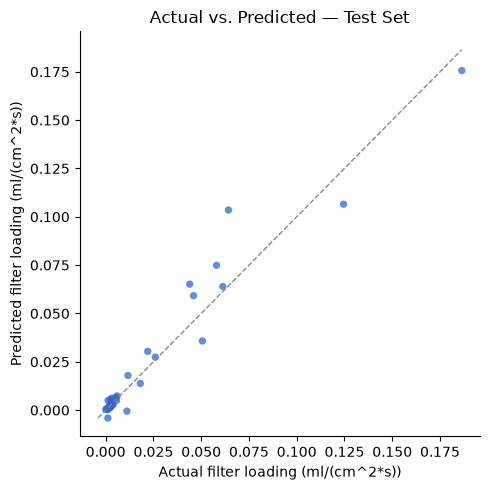

In [11]:
y_pred_test = model.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, y_pred_test, s=28, alpha=0.75, color="#3366CC", edgecolor="none")

lo = min(y_test.min(), y_pred_test.min())
hi = max(y_test.max(), y_pred_test.max())
ax.plot([lo, hi], [lo, hi], color="#888888", linewidth=1, linestyle="--")

ax.set_xlabel("Actual filter loading (ml/(cm^2*s))")
ax.set_ylabel("Predicted filter loading (ml/(cm^2*s))")
ax.set_title("Actual vs. Predicted — Test Set")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()
